# History matching pipeline (draft): pick the top 10 cases

**Role:** data scientist, history matching (Step 4 of the workflow).
**Status:** DRAFT. It is tested on 25 real simulated cases. It is ready to receive the proxy team's predictions.

## What this notebook does

```
 predicted curves (cases x dates x oil/water[/gas])  +  observed history
                          |
        [0] align dates, keep oil + water, scale
                          |
          +---------------+----------------+
          |                                |
   [A] DISCRETE RANKING            [B] BAYESIAN MCMC (reference paper)
   score each given case           sample the 4 parameters (emcee)
   posterior weight per case       proxy(theta) -> curves
          |                                |
          +---------------+----------------+
                          |
        [C] choose 10 (good AND not near-copies)
                          |
        [D] quality checks, plots, export top-10 time series
```

* **Input:** the predicted cumulative production time series of 1 to 100 cases, and the observed history.
* **Output:** the top 10 cases with their full time series and a mismatch score. The 10 series feed template tabs `Case 1` to `Case 10`.
* **Method:** Bayesian inversion with MCMC, as in *Zhang et al., SPE Journal 2023* (Robust history matching with Bayesian inversion and an LSTM proxy). The sampler is the affine-invariant ensemble sampler (`emcee`, same stretch move as the paper's Algorithm 1).

## How to use it with the real proxy output (hand-over)

**One input folder, one output folder.** No code needs to change.

1. Put the proxy team's files in `solution/histmatch_input/` (format in the `README.md` inside that folder):
   * `predictions.csv`: columns `case_id, date, oil_cum, water_cum` (and `gas_cum` if available). Dates can run past 2008. The history window is used for matching. Later dates are carried to the output.
   * `case_params.csv`: columns `case_id, fault_trans, poro_mult, perm_mult, aquifer_pv`. Needed for method B.
   * `history.csv` (optional): the observed history. If absent, `solution/output/history_observed.csv` is used.
2. Run all cells. If the input folder is empty, the notebook runs a **draft demo** on 25 real simulated cases instead.
3. Read the results in `solution/histmatch_output/`. The main files are `top10_cases_<tag>.csv` (the 10 chosen cases with their mismatch scores and parameters) and `top10_series_<tag>.csv` (their full time series).
4. Optional: pass your own proxy function in `PROXY` (section 10). If you do not, the notebook builds a stand-in proxy from the supplied cases.

## Key design choices

| Choice | Reason |
|---|---|
| Match **cumulative oil and water** only | Gas = 0.3633 x oil in every case, so gas would count oil twice. Cumulatives avoid the rate-convention mismatch between the history and the cases. |
| Scale each quantity by the observed value at the last history date | Oil and water count equally. The score reads as a share of the final cumulative. |
| **Headline score** = combined normalised RMSE (NRMSE) of oil and water | Same idea as the paper's RMSE check (threshold 0.003 on recovery factor). |
| Noise level **sampled**, plus proxy error added | The history has no stated error. The paper also infers the error. |
| Optional AR(1) correlation of residuals | Errors on cumulative curves are strongly correlated in time. Treating them as independent makes the posterior too narrow. `rho=0` gives the paper's independent version. |

In [1]:
import warnings, time
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import emcee
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*The optimal value found for dimension.*")

HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "solution" / "output").exists())
OUT_DIR = ROOT / "solution" / "output"                 # engineered data (made by notebook 1)
INPUT_DIR = ROOT / "solution" / "histmatch_input"      # ONE input folder: the proxy team's files go here
HM_DIR = ROOT / "solution" / "histmatch_output"        # ONE output folder: the top-10 cases and scores
INPUT_DIR.mkdir(exist_ok=True)
HM_DIR.mkdir(exist_ok=True)
TEMPLATE_PATH = next(p for p in [ROOT / "new_edited_dataset" / "09 Template Deliverable.xlsx",
                                 ROOT / "dataset" / "09 Template Deliverable.xlsx"] if p.exists())   # corrected copy first

PARAMS = ["fault_trans", "poro_mult", "perm_mult", "aquifer_pv"]
ALL_Q = ("gas_cum", "oil_cum", "water_cum")           # order used in the engineered arrays
GAS_OIL_RATIO = 0.3633                                 # cumulative gas / cumulative oil, fixed in all cases


@dataclass
class HMConfig:
    """All settings of the pipeline in one place."""
    match_quantities: tuple = ("oil_cum", "water_cum")  # gas is left out on purpose (= 0.3633 x oil)
    rho: object = "auto"            # AR(1) correlation of residuals: "auto", or a number in [0, 0.99]. 0 = paper.
    n_ensembles: int = 4            # independent emcee ensembles (like the paper's several chains)
    n_walkers: int = 16             # walkers per ensemble (must be >= 2 x number of dimensions)
    n_steps: int = 12000            # steps per walker (paper: 1,200; our chains correlate for ~150 steps, so ~80 autocorrelation times)
    burn_frac: float = 0.5          # share of steps thrown away (paper: 50 %)
    prior: str = "uniform"          # "uniform" (paper default) or "triangular" (mode at mid-range)
    prior_pad: float = 0.05         # widen the train bounds by 5 % of the range on each side
    log_sigma_range: tuple = (float(np.log(1e-4)), float(np.log(0.1)))   # prior on the noise level (relative)
    method: str = "A"               # how to rank cases: "A" (curves; best in tests T1/T2), "B" (posterior), "hybrid" (mean of both ranks)
    n_top: int = 10
    min_sep: float = 0.05           # min distance (0-1 scaled parameter space) between two chosen cases
    accept_nrmse: float = 0.01      # PROVISIONAL acceptance level for the best case (1 % of final cumulative; the best of 85 known cases is 0.49 %)
    seed: int = 0


print("root:", ROOT)
print("emcee", emcee.__version__)

root: C:\Users\Yi Siang\Documents\UM\dwc26
emcee 3.1.6


## 1. Data containers and loaders

Two small containers hold the inputs. `CaseSet` holds the predicted curves of many cases. `History` holds the observed field history.
The curves can have any dates. Only the dates that overlap the history are used for matching.

In [2]:
@dataclass
class CaseSet:
    """Predicted production time series of several cases."""
    case_ids: np.ndarray                 # (n,)
    dates: np.ndarray                    # (T,) datetime64[D], increasing
    curves: dict                         # name -> (n, T) cumulative values, e.g. "oil_cum"
    params: pd.DataFrame = None          # index = case_id, columns = PARAMS (needed for method B)


@dataclass
class History:
    """Observed field history."""
    dates: np.ndarray                    # (T,) datetime64[D]
    curves: dict                         # name -> (T,)


def caseset_from_array(Y, dates, case_ids, quantities=ALL_Q, params=None):
    """Y has shape (n_cases, n_dates, n_quantities)."""
    dates = np.asarray(dates).astype("datetime64[D]")
    curves = {q: np.asarray(Y[:, :, j], float) for j, q in enumerate(quantities)}
    return CaseSet(np.asarray(case_ids), dates, curves, params)


def caseset_from_long(df, params=None):
    """df has columns case_id, date and any of gas_cum, oil_cum, water_cum (one row per case and date)."""
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    qs = [q for q in ALL_Q if q in df.columns]
    ids = np.sort(df["case_id"].unique())
    dates = np.sort(df["date"].unique())
    curves = {}
    for q in qs:
        piv = df.pivot(index="case_id", columns="date", values=q).loc[ids, dates]
        if piv.isna().any().any():
            raise ValueError(f"{q}: not every case has a value on every date")
        curves[q] = piv.to_numpy(float)
    return CaseSet(ids, dates.astype("datetime64[D]"), curves, params)


def load_history(path=OUT_DIR / "history_observed.csv"):
    h = pd.read_csv(path, parse_dates=["date"])
    return History(h["date"].values.astype("datetime64[D]"), {q: h[q].to_numpy(float) for q in ALL_Q if q in h.columns})


def load_bounds(path=OUT_DIR / "param_bounds.csv"):
    return pd.read_csv(path).set_index("parameter").loc[PARAMS]

## 2. Preprocessing: put the cases on the history window

* The window starts at the first date where the history has oil (the early quarters are all zero).
* If the cases use other dates, the cumulative values are interpolated onto the history dates.
* Each quantity is scaled by the observed value on the last window date.
* Dates after the history are not used for matching. They stay in `CaseSet` and are exported later.

In [3]:
@dataclass
class Window:
    case_ids: np.ndarray
    dates: np.ndarray            # (Tw,) the matching dates
    quantities: list
    Yc: np.ndarray               # (n, Tw, Q) predicted cumulative curves in real units
    Yh: np.ndarray               # (Tw, Q) observed
    scale: np.ndarray            # (Q,) observed value on the last window date


def check_inputs(cs, hist, quantities):
    """Stop early, with a clear message, when the input does not fit the pipeline."""
    for q in quantities:
        if q not in cs.curves:
            raise ValueError(f"Predictions are missing '{q}'. Found: {list(cs.curves)}")
        if q not in hist.curves:
            raise ValueError(f"History is missing '{q}'")
        a = cs.curves[q]
        if a.shape != (len(cs.case_ids), len(cs.dates)):
            raise ValueError(f"{q}: shape {a.shape} does not match (n_cases, n_dates) = {(len(cs.case_ids), len(cs.dates))}")
        if not np.isfinite(a).all():
            raise ValueError(f"{q}: contains NaN or infinite values")
    if not (np.diff(cs.dates.astype("int64")) > 0).all():
        raise ValueError("Prediction dates must be strictly increasing")
    if len(np.unique(cs.case_ids)) != len(cs.case_ids):
        raise ValueError("case_id values must be unique")
    if cs.params is not None:
        if not set(PARAMS) <= set(cs.params.columns):
            raise ValueError(f"params must have columns {PARAMS}")
        missing = set(cs.case_ids) - set(cs.params.index)
        if missing:
            raise ValueError(f"params are missing for case_id {sorted(missing)[:10]}")


def align_window(cs, hist, quantities):
    quantities = list(quantities)
    check_inputs(cs, hist, quantities)
    first = int(np.argmax(hist.curves[quantities[0]] > 0))
    wd = hist.dates[first:]
    if wd[0] < cs.dates[0] or wd[-1] > cs.dates[-1]:
        raise ValueError(f"Predictions span {cs.dates[0]} to {cs.dates[-1]} but the history window is {wd[0]} to {wd[-1]}")
    exact = np.isin(wd, cs.dates)
    n = len(cs.case_ids)
    Yc = np.empty((n, len(wd), len(quantities)))
    for j, q in enumerate(quantities):
        A = cs.curves[q]
        if exact.all():
            Yc[:, :, j] = A[:, np.searchsorted(cs.dates, wd)]
        else:                                           # interpolate cumulative values onto the history dates
            dc = (cs.dates - cs.dates[0]).astype(float)
            dw = (wd - cs.dates[0]).astype(float)
            for i in range(n):
                Yc[i, :, j] = np.interp(dw, dc, A[i])
    Yh = np.column_stack([hist.curves[q][first:] for q in quantities])
    scale = Yh[-1].copy()
    if (scale <= 0).any():
        raise ValueError("Observed history is zero on the last date; cannot scale")
    return Window(cs.case_ids, wd, quantities, Yc, Yh, scale)

## 3. Mismatch metrics (method A)

For each case, the residual is `(observed - predicted) / scale`, so it is a share of the final cumulative.

| Column | Meaning |
|---|---|
| `nrmse_oil`, `nrmse_water` | Root-mean-square residual over the window |
| **`score`** | **Headline mismatch** = sqrt(mean of the squared NRMSEs of the matched quantities). Lower is better. |
| `max_rel_err` | Worst single residual (any quantity, any date) |
| `err_final_oil`, `err_final_water` | Signed residual on the last date (positive = predicted too high) |
| `loglik`, `weight` | Log-likelihood with the noise level integrated out, and the normalised posterior weight of each case |

**Residual correlation.** A cumulative curve error is smooth in time, so neighbouring residuals are alike. An AR(1) filter (`rho`) removes this before the likelihood is formed. With `rho = 0` the filter does nothing.

In [4]:
def whiten(R, rho):
    """AR(1) pre-whitening along the time axis (axis -2). rho = 0 returns R unchanged."""
    E = np.empty_like(R)
    E[..., 0, :] = np.sqrt(1.0 - rho ** 2) * R[..., 0, :]
    E[..., 1:, :] = R[..., 1:, :] - rho * R[..., :-1, :]
    return E


def estimate_rho(R, cap=0.95):
    """Lag-1 autocorrelation of residuals, pooled. R has shape (k, T, Q)."""
    num = (R[:, 1:, :] * R[:, :-1, :]).sum()
    den = (R ** 2).sum()
    return float(np.clip(num / den, 0.0, cap)) if den > 0 else 0.0


def loglik_marginal(R, rho):
    """Gaussian log-likelihood with the noise level integrated out (1/sigma prior). Constants dropped."""
    E = whiten(R, rho)
    n = R.shape[-2]
    rss = (E ** 2).sum(axis=-2) + 1e-300
    return (-0.5 * n * np.log(rss)).sum(axis=-1)


def score_cases(win, rho):
    """Method A. One row per case, indexed by case_id."""
    R = (win.Yc - win.Yh[None]) / win.scale                      # (n, T, Q) share of final cumulative
    names = [q.replace("_cum", "") for q in win.quantities]
    nr = np.sqrt((R ** 2).mean(axis=1))                          # (n, Q)
    df = pd.DataFrame(index=pd.Index(win.case_ids, name="case_id"))
    for j, nm in enumerate(names):
        df[f"nrmse_{nm}"] = nr[:, j]
    df["score"] = np.sqrt((nr ** 2).mean(axis=1))
    df["max_rel_err"] = np.abs(R).max(axis=(1, 2))
    for j, nm in enumerate(names):
        df[f"err_final_{nm}"] = R[:, -1, j]
    ll = loglik_marginal(R, rho)
    w = np.exp(ll - ll.max())
    df["loglik"] = ll
    df["weight"] = w / w.sum()
    df["rank_A"] = df["score"].rank(method="first").astype(int)
    return df

## 4. Forward model for method B: the proxy

Method B needs a function `proxy(theta) -> curves` for any parameter set `theta`, because the sampler visits many parameter sets that are not among the supplied cases.

* **Real use:** pass the proxy team's model. Contract: `proxy(theta)` takes an array `(m, 4)` in real units (order `fault_trans, poro_mult, perm_mult, aquifer_pv`) and returns `(m, Tw, Q)`, the cumulative curves in real units on the window dates, quantities in the order of `cfg.match_quantities`.
* **Stand-in (draft):** if no proxy is given, the notebook fits a *stand-in*: PCA on the curves, then one Gaussian process (Matern 5/2 kernel, one length scale per parameter) per PCA score. It is trained on the supplied cases only.
* The stand-in reports its own **cross-validated error** (`sigma_proxy`). The sampler adds it to the noise level, so a weak proxy gives a wider (more honest) posterior. This is the paper's "model inaccuracy" term.

In [5]:
def _fit_pca_gp(Z, F, max_comp, var_keep, seed):
    pca = PCA(n_components=min(max_comp, F.shape[0] - 1)).fit(F)
    k = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), var_keep) + 1)
    k = max(2, min(k, pca.n_components_))
    S = pca.transform(F)[:, :k]
    gps = []
    for j in range(k):
        kern = (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(np.ones(Z.shape[1]), (0.1, 100.0), nu=2.5)
                + WhiteKernel(1e-5, (1e-9, 1e-1)))
        gps.append(GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=2,
                                            random_state=seed).fit(Z, S[:, j]))
    return pca, k, gps


def _predict_pca_gp(model, Z):
    pca, k, gps = model
    S = np.column_stack([g.predict(Z) for g in gps])
    return S @ pca.components_[:k] + pca.mean_


class StandInProxy:
    """PCA + Gaussian-process stand-in for the proxy. Call it with theta (m, 4) in real units."""

    def __init__(self, theta, curves, scale, lo, hi, cv_folds=5, seed=0, max_comp=6, var_keep=0.9999):
        self.lo, self.hi, self.scale = np.asarray(lo), np.asarray(hi), np.asarray(scale)
        self.T, self.Q = curves.shape[1:]
        self.max_comp, self.var_keep, self.seed = max_comp, var_keep, seed
        self.model = _fit_pca_gp(self._z(theta), self._flat(curves), max_comp, var_keep, seed)
        self.n_comp = self.model[1]
        self.sigma_proxy = self._cv(theta, curves, cv_folds) if cv_folds else np.zeros(self.Q)

    def _z(self, theta):
        return (np.atleast_2d(theta) - self.lo) / (self.hi - self.lo)

    def _flat(self, curves):
        return (curves / self.scale).reshape(len(curves), -1)

    def _cv(self, theta, curves, folds):
        n = len(curves)
        folds = min(folds, n)
        idx = np.random.default_rng(self.seed).permutation(n)
        err = np.empty_like(curves)
        for f in range(folds):
            te = idx[f::folds]
            tr = np.setdiff1d(idx, te)
            m = _fit_pca_gp(self._z(theta[tr]), self._flat(curves[tr]), self.max_comp, self.var_keep, self.seed)
            pred = _predict_pca_gp(m, self._z(theta[te])).reshape(len(te), self.T, self.Q) * self.scale
            err[te] = pred - curves[te]
        return np.maximum(np.sqrt(((err / self.scale) ** 2).mean(axis=(0, 1))), 1e-4)

    def __call__(self, theta):
        F = _predict_pca_gp(self.model, self._z(theta))
        return F.reshape(len(F), self.T, self.Q) * self.scale

## 5. Bayesian model and MCMC (method B)

Model (paper Eq. 4): `observation = proxy(theta) + noise`, with Gaussian noise.

* **Unknowns:** the 4 parameters `theta` and one noise level per matched quantity (6 numbers for oil + water). The noise levels are sampled on a log scale.
* **Prior:** uniform on the train bounds widened by 5 % (the paper's default when nothing else is known). `prior="triangular"` is an alternative for the prior-sensitivity test (paper, Appendix C).
* **Likelihood:** Gaussian, residuals scaled by the final observed value, AR(1) correlation `rho`. The effective noise is `sqrt(sigma^2 + sigma_proxy^2)`.
* **Sampler:** affine-invariant ensemble sampler (`emcee`). Several independent ensembles start from spread-out points. The first half of each run is discarded.
* **Checks:** acceptance rate, autocorrelation time, effective sample size, and split R-hat across all walkers (a value close to 1.0 means the walkers agree; below 1.1 is the usual rule).

In [6]:
class LogPosterior:
    """Vectorised log-posterior for emcee. A row of X is [theta (4), log sigma (one per matched quantity)]."""

    def __init__(self, proxy, win, rho, cfg, bounds):
        self.proxy, self.win, self.rho, self.cfg = proxy, win, rho, cfg
        rng_ = (bounds["train_max"] - bounds["train_min"]).to_numpy()
        self.lo = bounds["train_min"].to_numpy() - cfg.prior_pad * rng_
        self.hi = bounds["train_max"].to_numpy() + cfg.prior_pad * rng_
        self.Q = len(win.quantities)
        self.ndim = 4 + self.Q
        sp = getattr(proxy, "sigma_proxy", None)
        self.sigma_proxy = np.zeros(self.Q) if sp is None else np.asarray(sp, float)

    def log_prior(self, X):
        th, ls = X[:, :4], X[:, 4:]
        a, b = self.cfg.log_sigma_range
        ok = ((th >= self.lo) & (th <= self.hi)).all(1) & ((ls >= a) & (ls <= b)).all(1)
        lp = np.where(ok, 0.0, -np.inf)
        if self.cfg.prior == "triangular":
            u = np.clip((th - self.lo) / (self.hi - self.lo), 1e-12, 1 - 1e-12)
            lp = lp + np.where(ok, np.log(np.maximum(1 - np.abs(2 * u - 1), 1e-12)).sum(1), 0.0)
        return lp

    def log_like(self, R, ls):
        n = R.shape[1]
        s2 = np.exp(2 * ls) + self.sigma_proxy ** 2            # (m, Q) effective variance
        E = whiten(R, self.rho)
        rss = (E ** 2).sum(axis=1)                              # (m, Q)
        c = 1.0 - self.rho ** 2
        return (-0.5 * n * np.log(s2) - 0.5 * (n - 1) * np.log(c) - rss / (2 * s2 * c)).sum(1)

    def __call__(self, X):
        X = np.atleast_2d(X)
        out = np.full(len(X), -np.inf)
        lp = self.log_prior(X)
        ok = np.isfinite(lp)
        if ok.any():
            pred = self.proxy(X[ok, :4])
            R = (self.win.Yh[None] - pred) / self.win.scale
            ll = self.log_like(R, X[ok, 4:])
            out[ok] = np.where(np.isfinite(ll), lp[ok] + ll, -np.inf)
        return out


def split_rhat(c):
    """Split R-hat. c has shape (steps, chains, dims). Returns one value per dimension."""
    n = c.shape[0] // 2
    s = np.concatenate([c[:n], c[n:2 * n]], axis=1)
    W = s.var(axis=0, ddof=1).mean(axis=0)
    B = n * s.mean(axis=0).var(axis=0, ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)


def run_mcmc(logpost, cfg, seed):
    """Several independent emcee ensembles. Returns chain (steps, walkers_total, dims), logp, and acceptance rates."""
    rs = np.random.RandomState(seed)
    chains, logps, accs, taus = [], [], [], []
    a, b = cfg.log_sigma_range
    for e in range(cfg.n_ensembles):
        p0 = np.empty((cfg.n_walkers, logpost.ndim))
        p0[:, :4] = logpost.lo + rs.rand(cfg.n_walkers, 4) * (logpost.hi - logpost.lo)       # spread over the prior box
        p0[:, 4:] = np.log(10.0 ** rs.uniform(-3.5, -1.7, (cfg.n_walkers, logpost.Q)))       # noise 0.03 % to 2 %
        p0[:, 4:] = np.clip(p0[:, 4:], a + 1e-6, b - 1e-6)
        s = emcee.EnsembleSampler(cfg.n_walkers, logpost.ndim, logpost, vectorize=True)
        s.random_state = np.random.RandomState(seed * 1000 + e).get_state()
        s.run_mcmc(p0, cfg.n_steps, progress=False)
        chains.append(s.get_chain())
        logps.append(s.get_log_prob())
        accs.append(float(np.mean(s.acceptance_fraction)))
        burn = int(cfg.burn_frac * cfg.n_steps)
        taus.append(emcee.autocorr.integrated_time(s.get_chain(discard=burn), tol=0, quiet=True))
    return np.concatenate(chains, axis=1), np.concatenate(logps, axis=1), accs, np.array(taus)

## 6. The pipeline function: rank, sample, choose 10

`run_history_matching` does everything in one call:

1. align the cases to the history window and score every case (method A);
2. if the parameters of the cases are known, fit or take the proxy and run the MCMC (method B);
3. rank the cases by method A, by method B (distance to the posterior in parameter space), or by the mean of both ranks (`hybrid`);
4. choose the top 10. Two cases closer than `min_sep` in the 0-1 scaled parameter space count as near-copies. The lower-ranked one is skipped.

Which ranking is the default (`cfg.method`) is decided by the tests in section 11.

In [7]:
@dataclass
class HMResult:
    cfg: HMConfig
    cs: CaseSet
    hist: History
    win: Window
    rho: float
    scores: pd.DataFrame                  # all cases: metrics and ranks
    top: pd.DataFrame                     # the chosen cases, rank 1..n
    top_series: pd.DataFrame              # full time series of the chosen cases (all dates supplied)
    posterior: dict = None                # None when method B did not run
    proxy: object = None
    notes: list = field(default_factory=list)


def scaled_params(cs, bounds):
    p = cs.params.loc[cs.case_ids, PARAMS]
    return (p - bounds["train_min"]) / (bounds["train_max"] - bounds["train_min"])


def choose_top(scores, pscaled, method, n_top, min_sep):
    """Walk down the ranking and skip cases that are near-copies of an already chosen case."""
    col = {"A": "rank_A", "B": "rank_B", "hybrid": "rank_hybrid"}[method]
    if col not in scores:
        col = "rank_A"
    order = scores.sort_values([col, "score"]).index.to_list()
    chosen = []
    for cid in order:
        if len(chosen) == n_top:
            break
        if pscaled is None or all(np.linalg.norm(pscaled.loc[cid].to_numpy() - pscaled.loc[j].to_numpy()) >= min_sep
                                  for j in chosen):
            chosen.append(cid)
    for cid in order:                                     # not enough distinct cases: fill from the ranking
        if len(chosen) == min(n_top, len(order)):
            break
        if cid not in chosen:
            chosen.append(cid)
    return chosen


def build_series(cs, ids):
    """Long table with the full supplied time series of the chosen cases. Gas is derived from oil if missing."""
    rows = []
    for rank, cid in enumerate(ids, 1):
        i = int(np.where(cs.case_ids == cid)[0][0])
        d = pd.DataFrame({"rank": rank, "case_id": cid, "date": cs.dates})
        for q in ALL_Q:
            d[q] = cs.curves[q][i] if q in cs.curves else np.nan
        d["gas_is_derived"] = "gas_cum" not in cs.curves
        if d["gas_is_derived"].iloc[0] and "oil_cum" in cs.curves:
            d["gas_cum"] = GAS_OIL_RATIO * d["oil_cum"]
        rows.append(d)
    return pd.concat(rows, ignore_index=True)


def posterior_summary(flat, lo, hi, q_names):
    rows = []
    names = PARAMS + [f"sigma_{q.replace('_cum', '')}" for q in q_names]
    for j, nm in enumerate(names):
        x = flat[:, j] if j < 4 else np.exp(flat[:, j])
        prior_sd = (hi[j] - lo[j]) / np.sqrt(12) if j < 4 else np.nan
        rows.append({"parameter": nm, "mean": x.mean(), "sd": x.std(), "p05": np.percentile(x, 5),
                     "p50": np.percentile(x, 50), "p95": np.percentile(x, 95),
                     "sd_ratio_vs_prior": x.std() / prior_sd if j < 4 else np.nan})
    s = pd.DataFrame(rows).set_index("parameter")
    s["well_determined"] = np.where(s["sd_ratio_vs_prior"] < 0.5, "yes", np.where(s["sd_ratio_vs_prior"].isna(), "", "no"))
    return s


def nrmse_vs(pred, win):
    R = (pred - win.Yh) / win.scale
    return float(np.sqrt((np.sqrt((R ** 2).mean(axis=0)) ** 2).mean()))


def run_history_matching(cs, hist, cfg, bounds, proxy=None, true_theta=None, verbose=True):
    t0 = time.time()
    log = []
    say = (lambda s: (print(s), log.append(s))) if verbose else (lambda s: log.append(s))
    win = align_window(cs, hist, cfg.match_quantities)
    n = len(win.case_ids)
    say(f"[0] {n} case(s); matching window {win.dates[0]} to {win.dates[-1]} ({len(win.dates)} dates); "
        f"quantities {win.quantities}")

    # ---- Method A: score every case
    R_raw = (win.Yc - win.Yh[None]) / win.scale
    if cfg.rho == "auto":
        best = np.argsort(np.sqrt((R_raw ** 2).mean(axis=(1, 2))))[:min(5, n)]
        rho = estimate_rho(R_raw[best])
    else:
        rho = float(cfg.rho)
    scores = score_cases(win, rho)
    say(f"[A] residual correlation rho = {rho:.2f}; best case {scores['score'].idxmin()} "
        f"with score {scores['score'].min():.4f}")

    # ---- Method B: Bayesian MCMC (needs parameters and a proxy)
    post = None
    pscaled = scaled_params(cs, bounds) if cs.params is not None else None
    can_b = n >= 8 and (pscaled is not None or proxy is not None)
    if proxy is None and cs.params is not None and n >= 8:
        th = cs.params.loc[cs.case_ids, PARAMS].to_numpy()
        proxy = StandInProxy(th, win.Yc, win.scale, bounds["train_min"].to_numpy(), bounds["train_max"].to_numpy(),
                             seed=cfg.seed)
        say(f"[B] stand-in proxy fitted on {n} cases: {proxy.n_comp} PCA scores; "
            f"cross-validated error (share of final) = {np.round(proxy.sigma_proxy, 4)}")
    if proxy is None or pscaled is None or n < 8:
        say("[B] skipped: needs at least 8 cases with parameters (or a proxy plus parameters). Ranking uses method A only.")
    else:
        lp = LogPosterior(proxy, win, rho, cfg, bounds)
        chain, logp, accs, taus = run_mcmc(lp, cfg, cfg.seed)
        burn = int(cfg.burn_frac * cfg.n_steps)
        postc = chain[burn:]
        rhat = split_rhat(postc)
        tau = taus.mean(axis=0)
        flat = postc.reshape(-1, lp.ndim)
        flat_lp = logp[burn:].reshape(-1)
        ess = len(flat) / max(1.0, float(tau.max()))
        names = PARAMS + [f"log_sigma_{q.replace('_cum', '')}" for q in win.quantities]
        diag = pd.DataFrame({"r_hat": rhat, "autocorr_time": tau}, index=names)
        summary = posterior_summary(flat, lp.lo, lp.hi, win.quantities)
        # distance of every case to the posterior in the identified directions (Mahalanobis, scaled parameter space)
        lo_t, hi_t = bounds["train_min"].to_numpy(), bounds["train_max"].to_numpy()
        zs = (flat[:, :4] - lo_t) / (hi_t - lo_t)
        mu, cov = zs.mean(0), np.cov(zs.T) + 1e-6 * np.eye(4)
        dz = pscaled.to_numpy() - mu
        scores["post_dist"] = np.sqrt(np.einsum("ij,jk,ik->i", dz, np.linalg.inv(cov), dz))
        scores["rank_B"] = scores["post_dist"].rank(method="first").astype(int)
        key = (scores["rank_A"] + scores["rank_B"]) / 2 + 1e-6 * scores["rank_A"]
        scores["rank_hybrid"] = key.rank(method="first").astype(int)
        th_mean = flat[:, :4].mean(0)
        th_map = flat[np.argmax(flat_lp), :4]
        pred_mean, pred_map = proxy(th_mean[None])[0], proxy(th_map[None])[0]
        draws = flat[np.random.default_rng(cfg.seed).choice(len(flat), 300, replace=False), :4]
        band = np.percentile(proxy(draws), [10, 50, 90], axis=0)               # (3, Tw, Q)
        post = dict(chain=chain, logp=logp, burn=burn, flat=flat, diag=diag, summary=summary, ess=ess,
                    acc=accs, mean=th_mean, map=th_map, pred_mean=pred_mean, pred_map=pred_map, band=band,
                    nrmse_mean=nrmse_vs(pred_mean, win), nrmse_map=nrmse_vs(pred_map, win),
                    sigma_proxy=lp.sigma_proxy, true_theta=true_theta)
        say(f"[B] MCMC: {cfg.n_ensembles} ensembles x {cfg.n_walkers} walkers x {cfg.n_steps} steps; "
            f"acceptance {np.mean(accs):.2f}; max R-hat {rhat.max():.3f}; max autocorr. time {tau.max():.0f}; "
            f"effective samples ~{ess:.0f}")
        say(f"[B] posterior-mean curve score {post['nrmse_mean']:.4f}; MAP curve score {post['nrmse_map']:.4f}")
        if rhat.max() > 1.1:
            say("[B] WARNING: R-hat above 1.1. Run longer (cfg.n_steps) before trusting the posterior.")

    # ---- Choose the top n
    method = cfg.method if post is not None else "A"
    ids = choose_top(scores, pscaled, method, cfg.n_top, cfg.min_sep)
    top = scores.loc[ids].copy()
    top.insert(0, "rank", np.arange(1, len(ids) + 1))
    top["meets_threshold"] = top["score"] <= cfg.accept_nrmse
    if cs.params is not None:
        top = top.join(cs.params.loc[ids, PARAMS])
    top_series = build_series(cs, ids)
    say(f"[C] method '{method}' chose {len(ids)} case(s): {ids}")
    if not top["meets_threshold"].iloc[0]:
        say(f"[D] WARNING: the best case has score {top['score'].iloc[0]:.4f}, above the provisional level "
            f"{cfg.accept_nrmse}. The supplied cases may not contain a good match.")
    say(f"done in {time.time() - t0:.1f} s")
    return HMResult(cfg, cs, hist, win, rho, scores, top, top_series, post, proxy, log)

## 7. Plots

Colours follow one scheme: **ink** = observed history, **blue** = our cases and the posterior, **orange** = a known true value (used in tests only). Blue steps show rank (dark = rank 1).

In [8]:
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_600, BLUE_450, BLUE_250, ORANGE = "#184f95", "#2a78d6", "#86b6ef", "#eb6834"
FIG_DIR = HM_DIR / "figs"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED})


def _ax(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    return ax


def _finish(fig, name, save=True):
    fig.tight_layout()
    if save and name:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=130)
    plt.show()


QLAB = {"oil_cum": "Oil cumulative [million STB]", "water_cum": "Water cumulative [million STB]",
        "gas_cum": "Gas cumulative [million MSCF]"}


def plot_fit(res, name=None):
    """Top: predicted curves of the chosen cases against the history. Bottom: residual in % of the final value."""
    cs, win, top = res.cs, res.win, res.top
    qs = win.quantities
    fig, axes = plt.subplots(2, len(qs), figsize=(5.6 * len(qs), 6.2), squeeze=False)
    ids = list(top["case_id"] if "case_id" in top else top.index)
    for j, q in enumerate(qs):
        ax = _ax(axes[0, j])
        for i, cid in enumerate(cs.case_ids):
            if cid not in ids:
                ax.plot(cs.dates, cs.curves[q][i] / 1e6, color=AXIS, lw=0.5, alpha=0.6, zorder=1)
        for r, cid in enumerate(ids):
            i = int(np.where(cs.case_ids == cid)[0][0])
            ax.plot(cs.dates, cs.curves[q][i] / 1e6, color=BLUE_600 if r == 0 else BLUE_250,
                    lw=1.8 if r == 0 else 1.1, zorder=3 if r == 0 else 2)
        ax.plot(res.hist.dates, res.hist.curves[q] / 1e6, color=INK, lw=1.8, zorder=4)
        ax.set_ylabel(QLAB[q]); ax.set_xlabel("Date")
        if j == 0:
            from matplotlib.lines import Line2D
            ax.legend(handles=[Line2D([], [], color=INK, lw=1.8, label="Observed history"),
                               Line2D([], [], color=BLUE_600, lw=1.8, label="Rank 1"),
                               Line2D([], [], color=BLUE_250, lw=1.1, label=f"Ranks 2-{len(ids)}"),
                               Line2D([], [], color=AXIS, lw=0.8, label="Other supplied cases")],
                      frameon=False, fontsize=8, loc="upper left")
        ax2 = _ax(axes[1, j])
        for r, cid in enumerate(ids):
            i = int(np.where(cs.case_ids == cid)[0][0])
            ax2.plot(win.dates, (win.Yc[i, :, j] - win.Yh[:, j]) / win.scale[j] * 100,
                     color=BLUE_600 if r == 0 else BLUE_250, lw=1.8 if r == 0 else 1.1)
        ax2.axhline(0, color=INK, lw=0.8)
        ax2.set_ylabel("Predicted - observed [% of final observed]"); ax2.set_xlabel("Date")
    fig.suptitle("Chosen cases against the observed history", x=0.01, ha="left", color=INK)
    _finish(fig, name)


def plot_scores(res, k=25, name=None):
    sc = res.scores.sort_values("score").head(k)
    chosen = set(res.top["case_id"] if "case_id" in res.top else res.top.index)
    fig, ax = plt.subplots(figsize=(6.5, 0.26 * len(sc) + 1.2))
    _ax(ax)
    colors = [BLUE_450 if cid in chosen else BLUE_250 for cid in sc.index]
    ax.barh([f"Case {c}" for c in sc.index][::-1], (sc["score"] * 100).to_numpy()[::-1], color=colors[::-1], height=0.65)
    ax.axvline(res.cfg.accept_nrmse * 100, color=INK, lw=0.9, ls="--")
    ax.text(res.cfg.accept_nrmse * 100, len(sc) - 0.3, " provisional accept level", fontsize=7.5, color=INK2, va="bottom")
    ax.set_xlabel("Mismatch score: NRMSE [% of final observed cumulative]")
    ax.set_title(f"Best {len(sc)} cases by score (dark blue = chosen)", loc="left", color=INK, fontsize=10)
    ax.grid(axis="y", visible=False)
    _finish(fig, name)


def plot_posterior(res, name=None):
    p = res.posterior
    if p is None:
        print("No posterior (method B did not run).")
        return
    flat = p["flat"][:: max(1, len(p["flat"]) // 2500), :4]
    lab = ["Fault transm.", "Porosity mult.", "Permeability mult.", "Aquifer PV"]
    top_ids = list(res.top["case_id"] if "case_id" in res.top else res.top.index)
    tp = res.cs.params.loc[top_ids, PARAMS].to_numpy() if res.cs.params is not None else None
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))
    for i in range(4):
        for j in range(4):
            ax = axes[i, j]
            if j > i:
                ax.axis("off"); continue
            _ax(ax)
            if i == j:
                ax.hist(flat[:, i], bins=30, color=BLUE_450, alpha=0.85, edgecolor=SURF, lw=0.4)
                ax.set_yticks([])
                if p["true_theta"] is not None:
                    ax.axvline(p["true_theta"][i], color=ORANGE, lw=1.5)
            else:
                ax.scatter(flat[:, j], flat[:, i], s=3, color=BLUE_450, alpha=0.15, linewidths=0)
                if tp is not None:
                    ax.scatter(tp[:, j], tp[:, i], s=22, facecolors="none", edgecolors=INK, linewidths=0.9)
                if p["true_theta"] is not None:
                    ax.scatter(p["true_theta"][j], p["true_theta"][i], marker="*", s=90, color=ORANGE, zorder=5)
            if i == 3: ax.set_xlabel(lab[j], fontsize=8)
            if j == 0 and i > 0: ax.set_ylabel(lab[i], fontsize=8)
    fig.suptitle("Posterior of the 4 parameters (blue). Open circles = chosen cases"
                 + (". Orange = true value." if p["true_theta"] is not None else "."), x=0.01, ha="left", color=INK, fontsize=10)
    _finish(fig, name)


def plot_trace(res, name=None, n_chains=12):
    p = res.posterior
    if p is None:
        return
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
    lab = ["Fault transm.", "Porosity mult.", "Permeability mult.", "Aquifer PV"]
    for j in range(4):
        ax = _ax(axes[j])
        ax.plot(p["chain"][:, :n_chains, j], color=BLUE_250, lw=0.5, alpha=0.8)
        ax.axvline(p["burn"], color=INK, lw=0.9, ls="--")
        ax.set_title(lab[j], fontsize=9, loc="left", color=INK2)
        ax.set_xlabel("Step")
    fig.suptitle("Chain traces (dashed line = end of burn-in)", x=0.01, ha="left", color=INK, fontsize=10)
    _finish(fig, name)


def plot_predictive(res, name=None):
    p = res.posterior
    if p is None:
        return
    win = res.win
    fig, axes = plt.subplots(1, len(win.quantities), figsize=(5.6 * len(win.quantities), 3.6), squeeze=False)
    for j, q in enumerate(win.quantities):
        ax = _ax(axes[0, j])
        ax.fill_between(win.dates, p["band"][0, :, j] / 1e6, p["band"][2, :, j] / 1e6, color=BLUE_250, alpha=0.6, lw=0)
        ax.plot(win.dates, p["band"][1, :, j] / 1e6, color=BLUE_450, lw=1.4)
        ax.plot(win.dates, win.Yh[:, j] / 1e6, color=INK, lw=1.6, ls="--")
        ax.set_ylabel(QLAB[q]); ax.set_xlabel("Date")
        if j == 0:
            from matplotlib.lines import Line2D
            from matplotlib.patches import Patch
            ax.legend(handles=[Line2D([], [], color=INK, lw=1.6, ls="--", label="Observed history"),
                               Line2D([], [], color=BLUE_450, lw=1.4, label="Posterior median"),
                               Patch(color=BLUE_250, alpha=0.6, label="Posterior P10-P90")],
                      frameon=False, fontsize=8, loc="upper left")
    fig.suptitle("Posterior prediction against the history", x=0.01, ha="left", color=INK, fontsize=10)
    _finish(fig, name)

## 8. Quality checks, export and template writer

* `nearest_case_check` stands in for the paper's final step (run the real simulator at the posterior mean). We have no simulator, but we do have real simulated cases that the pipeline never saw. The check finds the unseen case closest to the posterior mean and scores it against the history.
* `export_results` saves the top-10 table, the full series of the 10 cases, all scores and the posterior to `solution/histmatch_output/`.
* `write_template` fills the 10 template tabs when the series reach 01/01/2028. It only works once the proxy team (or the forecast step) supplies dates up to 2028. Gas is derived from oil if it is missing.

In [9]:
def nearest_case_check(res, ref_ids, cases, Y_all, dates, bounds):
    """Score the real simulated case (not used in the run) that is closest to the posterior mean."""
    p = res.posterior
    if p is None:
        return None
    lo, hi = bounds["train_min"].to_numpy(), bounds["train_max"].to_numpy()
    ref = cases.loc[ref_ids, PARAMS].to_numpy()
    d = np.linalg.norm((ref - p["mean"]) / (hi - lo), axis=1)
    cid = int(np.asarray(ref_ids)[np.argmin(d)])
    Y = Y_all[cid - 1]
    cs1 = caseset_from_array(Y[None], dates, [cid])
    w1 = align_window(cs1, res.hist, res.cfg.match_quantities)
    return dict(case_id=cid, distance_scaled=float(d.min()), score=float(score_cases(w1, res.rho)["score"].iloc[0]),
                posterior_mean_curve_score=p["nrmse_mean"])


def export_results(res, tag="draft"):
    res.top.to_csv(HM_DIR / f"top10_cases_{tag}.csv")
    res.top_series.to_csv(HM_DIR / f"top10_series_{tag}.csv", index=False)
    res.scores.to_csv(HM_DIR / f"scores_all_{tag}.csv")
    if res.posterior is not None:
        res.posterior["summary"].to_csv(HM_DIR / f"posterior_summary_{tag}.csv")
        res.posterior["diag"].to_csv(HM_DIR / f"mcmc_diagnostics_{tag}.csv")
        cols = PARAMS + [f"log_sigma_{q.replace('_cum', '')}" for q in res.win.quantities]
        pd.DataFrame(res.posterior["flat"][::10], columns=cols).to_csv(HM_DIR / f"posterior_samples_{tag}.csv", index=False)
    print("saved to", HM_DIR)


def write_template(top_series, template_path, out_path):
    """Fill tabs 'Case 1'..'Case 10' (rank k -> tab k). Needs every template date in the series."""
    import openpyxl
    wb = openpyxl.load_workbook(template_path)
    for rank in sorted(top_series["rank"].unique()):
        ws = wb[f"Case {rank}"]
        s = top_series[top_series["rank"] == rank].set_index(pd.to_datetime(top_series[top_series["rank"] == rank]["date"]))
        for r in range(2, ws.max_row + 1):
            d = pd.to_datetime(ws.cell(r, 1).value)
            if d not in s.index:
                raise ValueError(f"Case {rank}: the series has no value for template date {d.date()}")
            ws.cell(r, 2).value = float(s.loc[d, "gas_cum"])
            ws.cell(r, 3).value = float(s.loc[d, "oil_cum"])
            ws.cell(r, 4).value = float(s.loc[d, "water_cum"])
    wb.save(out_path)
    return out_path

## 9. Demo data: 25 real simulated cases

The draft is tested on real simulated curves (file `02`, as engineered in notebook 1; the 4 parameters come from file `01`).

* **Pipeline input (the "predicted production data"):** 25 cases drawn at random from the train cases 1-70.
* **Never used by the pipeline:** the remaining train cases and the validation cases. They act as extra "simulator" truth for the checks and as fake histories for the tests.
* **Locked:** test cases 86-100 are not touched.

In [10]:
cases = pd.read_csv(OUT_DIR / "cases.csv").set_index("case_id")
z = np.load(OUT_DIR / "curves_quarterly_cum.npz", allow_pickle=False)
Y_ALL = z["Y"]                                                   # (100, 41, 3): gas, oil, water; index = case_id - 1
DATES = np.array(z["dates"]).astype("datetime64[D]")
BOUNDS = load_bounds()

rng = np.random.default_rng(2026)
train_ids = cases.index[cases["split"] == "train"].to_numpy()
val_ids = cases.index[cases["split"] == "validation"].to_numpy()
DRAFT_IDS = np.sort(rng.choice(train_ids, 25, replace=False))
UNSEEN_IDS = np.setdiff1d(np.concatenate([train_ids, val_ids]), DRAFT_IDS)   # never given to the pipeline
print("draft cases (pipeline input):", DRAFT_IDS.tolist())
print("unseen cases (checks and tests):", len(UNSEEN_IDS), "- test cases 86-100 stay locked")

draft cases (pipeline input): [2, 5, 7, 9, 11, 19, 20, 24, 32, 35, 40, 41, 42, 44, 46, 47, 50, 54, 55, 62, 64, 65, 66, 67, 70]
unseen cases (checks and tests): 60 - test cases 86-100 stay locked


## 10. INPUT: the proxy team's predictions

The cell reads `solution/histmatch_input/`. If `predictions.csv` is there, it is a **real run**. If not, it is the **draft demo** (25 real simulated cases).
Everything below this cell works on the three objects `PRED_CASES`, `HISTORY` and `PROXY`.

In [11]:
PRED_FILE, PARAM_FILE, HIST_FILE = INPUT_DIR / "predictions.csv", INPUT_DIR / "case_params.csv", INPUT_DIR / "history.csv"
PROXY = None        # optional: a function proxy(theta (m,4)) -> (m, Tw, Q) cumulative curves in real units

if PRED_FILE.exists():                                              # ---- REAL RUN
    par = pd.read_csv(PARAM_FILE).set_index("case_id")[PARAMS] if PARAM_FILE.exists() else None
    PRED_CASES = caseset_from_long(pd.read_csv(PRED_FILE), params=par)
    HISTORY = load_history(HIST_FILE) if HIST_FILE.exists() else load_history()
    TAG = "real"
else:                                                               # ---- DRAFT DEMO
    PRED_CASES = caseset_from_array(Y_ALL[DRAFT_IDS - 1], DATES, DRAFT_IDS, params=cases.loc[DRAFT_IDS, PARAMS])
    HISTORY = load_history()
    TAG = "draft"
print(f"{TAG.upper()} run: {len(PRED_CASES.case_ids)} case(s), predictions from {PRED_CASES.dates[0]} to {PRED_CASES.dates[-1]}")

CFG = HMConfig()
res = run_history_matching(PRED_CASES, HISTORY, CFG, BOUNDS, proxy=PROXY)

DRAFT run: 25 case(s), predictions from 1998-01-01 to 2008-01-01
[0] 25 case(s); matching window 1999-01-01 to 2008-01-01 (37 dates); quantities ['oil_cum', 'water_cum']
[A] residual correlation rho = 0.92; best case 11 with score 0.0053


[B] stand-in proxy fitted on 25 cases: 3 PCA scores; cross-validated error (share of final) = [0.0025 0.0047]


[B] MCMC: 4 ensembles x 16 walkers x 12000 steps; acceptance 0.32; max R-hat 1.047; max autocorr. time 197; effective samples ~1952
[B] posterior-mean curve score 0.0076; MAP curve score 0.0070


[C] method 'A' chose 10 case(s): [11, 40, 50, 20, 24, 47, 65, 19, 35, 32]
done in 115.9 s


### Result: top 10 cases and their mismatch scores

In [12]:
show = res.top.copy()
for c in ["score", "nrmse_oil", "nrmse_water", "max_rel_err", "err_final_oil", "err_final_water"]:
    show[c] = (show[c] * 100).round(3)
show["weight"] = show["weight"].round(4)
if "post_dist" in show:
    show["post_dist"] = show["post_dist"].round(2)
print("Scores in % of the final observed cumulative (lower is better). err_final > 0: predicted too high.")
show.drop(columns=["loglik", "rank_A", "rank_B", "rank_hybrid"], errors="ignore").round(3)

Scores in % of the final observed cumulative (lower is better). err_final > 0: predicted too high.


,rank,nrmse_oil,nrmse_water,score,max_rel_err,err_final_oil,err_final_water,weight,post_dist,meets_threshold,fault_trans,poro_mult,perm_mult,aquifer_pv
case_id,,,,,,,,,,,,,,
11,1,0.239,0.715,0.533,2.635,0.880,-2.635,0.588,3.64,True,0.125,1.354,7.338,188.082
40,2,0.241,0.720,0.537,2.648,0.884,-2.648,0.406,4.33,True,0.144,1.354,4.961,132.522
50,3,0.273,0.817,0.609,3.056,1.020,-3.056,0.006,4.75,True,0.100,1.357,7.459,170.739
20,4,0.305,0.914,0.682,3.361,1.122,-3.361,0.000,5.87,True,0.062,1.361,5.078,123.383
24,5,0.773,2.316,1.726,4.071,-0.651,1.950,0.000,6.06,False,0.075,1.292,5.746,141.833
47,6,0.961,2.878,2.146,4.877,-0.997,2.986,0.000,7.68,False,0.065,1.258,9.502,112.686
65,7,1.090,3.118,2.335,5.249,-1.430,3.518,0.000,9.70,False,0.075,1.291,2.396,163.133
19,8,1.140,3.414,2.545,5.623,-1.323,3.964,0.000,10.17,False,0.101,1.237,8.764,82.994
35,9,1.235,3.699,2.758,9.127,3.048,-9.127,0.000,18.87,False,0.077,1.429,5.708,90.110


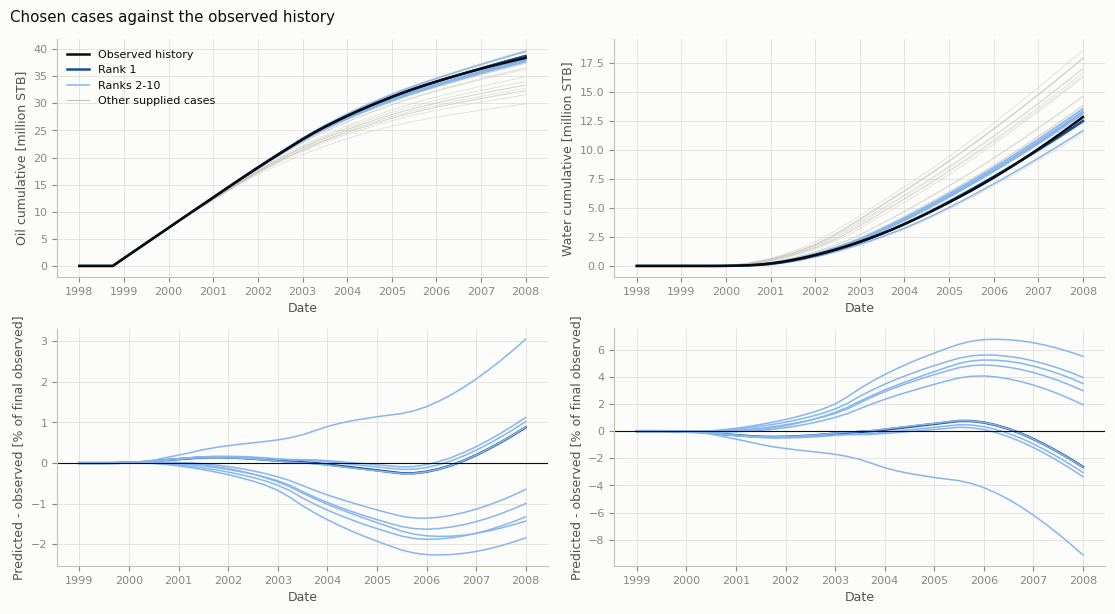

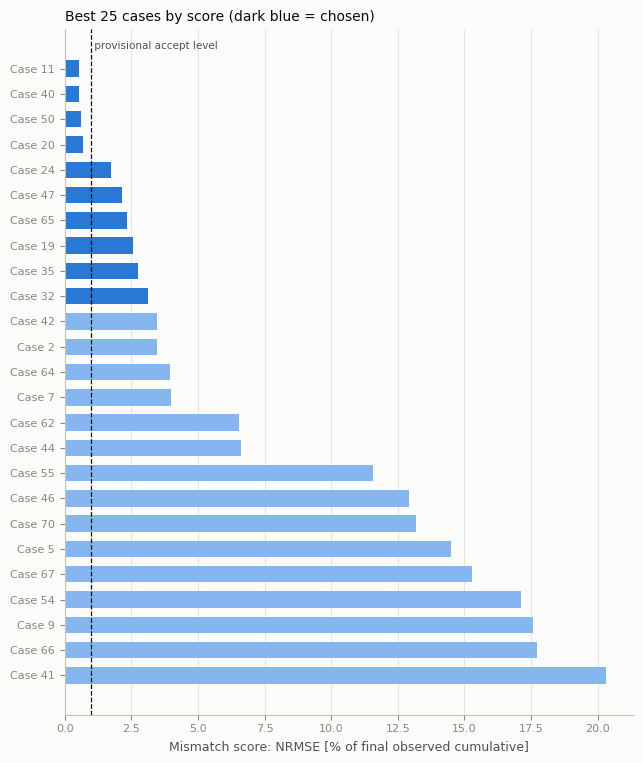

In [13]:
plot_fit(res, f"fit_top10_{TAG}")
plot_scores(res, 25, f"scores_{TAG}")

### Posterior: what the history tells us about the parameters

`sd_ratio_vs_prior` is the posterior spread divided by the prior spread. Below 0.5 means the history determines that parameter. Near 1 means the history says almost nothing about it.

In [14]:
if res.posterior is not None:
    print(res.posterior["summary"].round(4).to_string())
    print()
    print(res.posterior["diag"].round(3).to_string())

                 mean       sd      p05       p50       p95  sd_ratio_vs_prior well_determined
parameter                                                                                     
fault_trans    0.0986   0.0314   0.0511    0.0977    0.1489             0.9961              no
poro_mult      1.3297   0.0180   1.2992    1.3297    1.3590             0.0817             yes
perm_mult      4.5879   2.7733   0.5668    4.3023    9.3535             0.9743              no
aquifer_pv   128.0692  45.0454  56.3078  128.6447  198.6831             0.9724              no
sigma_oil      0.0003   0.0003   0.0001    0.0003    0.0009                NaN                
sigma_water    0.0015   0.0013   0.0001    0.0012    0.0040                NaN                

                 r_hat  autocorr_time
fault_trans      1.040        158.158
poro_mult        1.037        182.908
perm_mult        1.031        157.612
aquifer_pv       1.042        196.734
log_sigma_oil    1.047        156.412
log_sigma_w

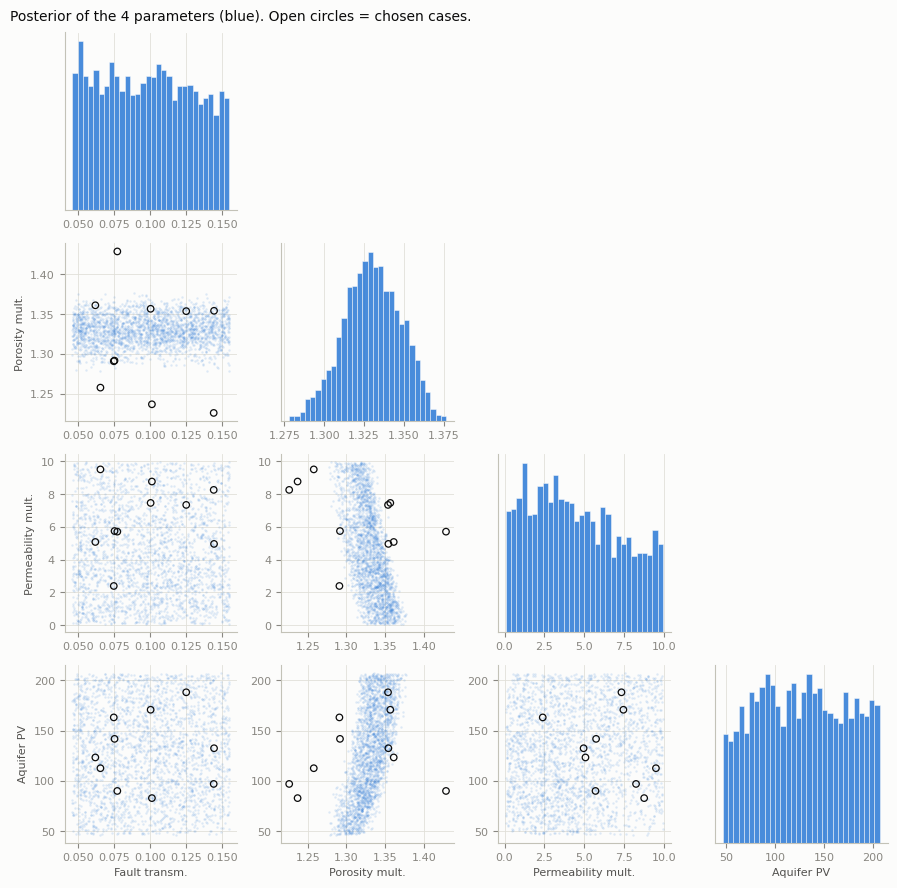

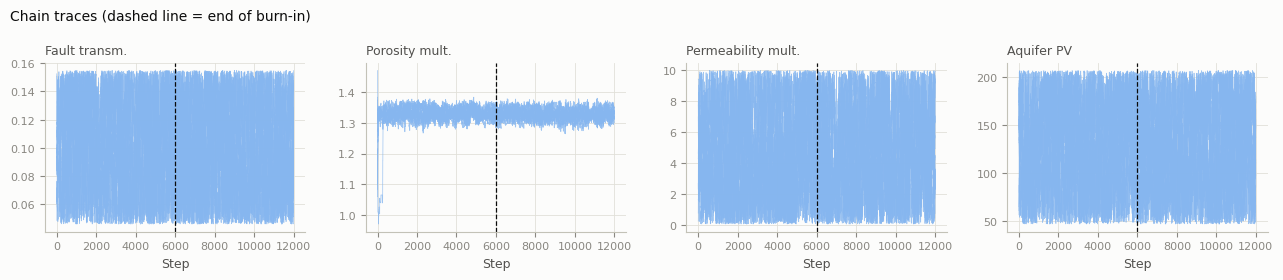

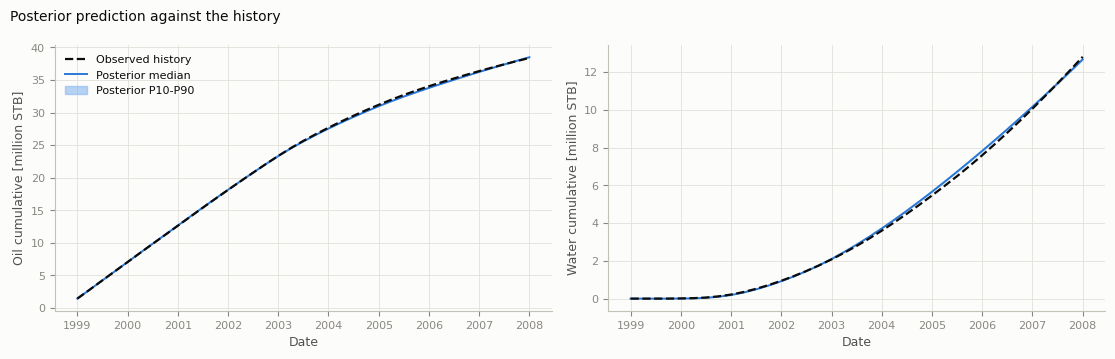

Unseen real case nearest to the posterior mean: {'case_id': 37, 'distance_scaled': 0.2144329295072374, 'score': 0.020058840766165712, 'posterior_mean_curve_score': 0.0075970352325287534}


saved to C:\Users\Yi Siang\Documents\UM\dwc26\solution\histmatch_output


In [15]:
plot_posterior(res, f"posterior_{TAG}")
plot_trace(res, f"trace_{TAG}")
plot_predictive(res, f"predictive_{TAG}")
if TAG == "draft":      # needs real simulated cases that the run never saw
    print("Unseen real case nearest to the posterior mean:", nearest_case_check(res, UNSEEN_IDS, cases, Y_ALL, DATES, BOUNDS))
export_results(res, TAG)

## 11. Tests

Five tests check that the pipeline works and show how much to trust it.

| # | Test | Question |
|---|---|---|
| T1 | **Fake-history recovery** | Use a known case as the "observed" history (with 0 %, 0.5 % and 2 % noise). Does the pipeline find the right cases and the right parameters? This copies the paper's synthetic-data test. |
| T2 | **Method A against B** | Which ranking gives the better top 10? |
| T3 | **One-case input** | Does it work when the proxy team supplies a single case? |
| T4 | **Scale check, 85 cases** | Does it run at the size of the final job (up to 100 cases)? |
| T5 | **Prior sensitivity** | Does the answer depend on the prior? (paper, Appendix C) |
| T6 | **Template writer** | Does it fill all 10 tabs to 2028 when the series are long enough? |

For T1 and T2 two kinds of fake history are used:

* **in-pool**: the fake history is one of the 25 supplied cases. The right answer is known: that case should rank first.
* **out-of-pool**: the fake history is an unseen validation case that is not among the 25. There is no exact match, so the question is how close the chosen cases get compared with the best the pool can offer (the "oracle": cases ranked on the noise-free fake history).

Noise is added to the cumulative curves as independent Gaussian errors, with a standard deviation of 0, 0.5 or 2 % of the final value. This is rougher than real noise, so it is a stress test.

In [16]:
from dataclasses import replace

# The tests always use the 25 draft cases, whatever is in the input folder, because only these have known truth.
CFG_T = replace(CFG, n_ensembles=2, n_steps=6000)      # lighter MCMC for the many test runs
TEST_POOL = caseset_from_array(Y_ALL[DRAFT_IDS - 1], DATES, DRAFT_IDS, params=cases.loc[DRAFT_IDS, PARAMS])
TEST_HIST = load_history()
_w = align_window(TEST_POOL, TEST_HIST, CFG_T.match_quantities)
T_PROXY = StandInProxy(cases.loc[DRAFT_IDS, PARAMS].to_numpy(), _w.Yc, _w.scale,
                       BOUNDS["train_min"].to_numpy(), BOUNDS["train_max"].to_numpy(), seed=CFG.seed)
PSCALED = scaled_params(TEST_POOL, BOUNDS)


def add_noise(y, rel_sd, rng_):
    if rel_sd == 0:
        return y.copy()
    return np.where(y > 0, np.maximum(y + rng_.normal(0, rel_sd * y[-1], len(y)), 0), 0.0)


def pseudo_history_test(true_id, noise, in_pool, seed):
    full = {q: Y_ALL[true_id - 1, :, j] for j, q in enumerate(ALL_Q)}
    r_ = np.random.default_rng(seed)
    clean = History(DATES, full)
    noisy = History(DATES, {q: (v if q == "gas_cum" else add_noise(v, noise, r_)) for q, v in full.items()})
    th_true = cases.loc[true_id, PARAMS].to_numpy(float)
    r = run_history_matching(TEST_POOL, noisy, CFG_T, BOUNDS, proxy=T_PROXY, true_theta=th_true, verbose=False)
    oracle = score_cases(align_window(TEST_POOL, clean, CFG_T.match_quantities), r.rho)
    o_top = oracle.sort_values("score").index[:10]
    row = dict(true_id=true_id, noise_pct=noise * 100, in_pool=in_pool, rho=r.rho,
               oracle_mean10=oracle.loc[o_top, "score"].mean() * 100, oracle_best=oracle["score"].min() * 100)
    for m, col in [("A", "rank_A"), ("B", "rank_B"), ("hybrid", "rank_hybrid")]:
        ids = choose_top(r.scores, PSCALED, m, 10, CFG_T.min_sep)
        row[f"overlap_{m}"] = len(set(ids) & set(o_top))
        row[f"mean10_{m}"] = oracle.loc[ids, "score"].mean() * 100
        row[f"best_{m}"] = oracle.loc[ids, "score"].min() * 100
        if in_pool:
            row[f"true_rank_{m}"] = int(r.scores.loc[true_id, col])
    p = r.posterior
    s = p["summary"]
    row["z_poro"] = (p["mean"][1] - th_true[1]) / s.loc["poro_mult", "sd"]
    row["cover_4"] = int(sum(s.loc[nm, "p05"] <= th_true[k] <= s.loc[nm, "p95"] for k, nm in enumerate(PARAMS)))
    row["poro_err_pct"] = (p["mean"][1] - th_true[1]) / th_true[1] * 100
    row["post_mean_curve_pct"] = nrmse_vs(p["pred_mean"], align_window(TEST_POOL, clean, CFG_T.match_quantities)) * 100
    row["max_rhat"] = p["diag"]["r_hat"].max()
    return row


t0 = time.time()
rows = []
in_ids = DRAFT_IDS[[3, 12, 20]]                                  # three of the supplied cases
out_ids = np.random.default_rng(7).choice(val_ids, 5, replace=False)   # five unseen validation cases
for noise in (0.0, 0.005, 0.02):
    for k, tid in enumerate(in_ids):
        rows.append(pseudo_history_test(int(tid), noise, True, 100 + k))
    for k, tid in enumerate(out_ids):
        rows.append(pseudo_history_test(int(tid), noise, False, 200 + k))
T1 = pd.DataFrame(rows)
print(f"{len(T1)} fake-history runs in {time.time() - t0:.0f} s")

24 fake-history runs in 612 s


### T1: in-pool fake history. Does the right case rank first?

`true_rank_*` is the position of the true case in the full ranking of each method (1 = first). `z_poro` is the error of the posterior mean porosity multiplier in posterior standard deviations. `cover_4` is how many of the 4 true parameters lie inside the posterior 5-95 % interval.

In [17]:
inp = T1[T1.in_pool]
print(inp[["true_id", "noise_pct", "true_rank_A", "true_rank_B", "true_rank_hybrid", "poro_err_pct", "z_poro", "cover_4", "max_rhat"]]
      .round(2).to_string(index=False))

 true_id  noise_pct  true_rank_A  true_rank_B  true_rank_hybrid  poro_err_pct  z_poro  cover_4  max_rhat
       9        0.0          1.0          2.0               1.0          4.63    0.38        4      9.64
      42        0.0          1.0          8.0               4.0         -0.63   -0.07        4      7.25
      64        0.0          1.0          2.0               1.0          2.37    1.89        3      1.10
       9        0.5          1.0          1.0               1.0          1.80    0.99        4      1.06
      42        0.5          1.0          2.0               1.0          2.32    1.22        4      1.07
      64        0.5          2.0          2.0               2.0          2.11    1.56        4      1.09
       9        2.0          1.0          1.0               1.0          1.52    0.79        4      1.05
      42        2.0          1.0          2.0               1.0          2.46    1.15        4      1.07
      64        2.0          2.0          3.0          

### T1 and T2: out-of-pool fake history. How close do the chosen cases get? Which method is best?

Scores are NRMSE in % of the final cumulative, measured against the **noise-free** fake history (so they are not hurt by the noise we added).
`oracle_mean10` is the best possible: the mean score of the 10 best cases of the pool. `mean10_*` is the mean score of the 10 cases each method chose. `overlap_*` counts how many of the oracle's 10 cases the method also found. A good method has `mean10` close to `oracle_mean10` and `overlap` close to 10.

In [18]:
out = T1[~T1.in_pool]
cols = ["oracle_mean10", "mean10_A", "mean10_B", "mean10_hybrid", "overlap_A", "overlap_B", "overlap_hybrid",
        "best_A", "best_B", "best_hybrid", "oracle_best"]
print("Mean over the 5 unseen fake histories, by noise level:")
print(out.groupby("noise_pct")[cols].mean().round(2).to_string())
print()
print("Posterior check, out-of-pool (porosity multiplier error, true values inside the 5-95 % interval):")
print(out.groupby("noise_pct")[["poro_err_pct", "z_poro", "cover_4", "post_mean_curve_pct", "max_rhat"]].agg(
    {"poro_err_pct": lambda x: np.abs(x).mean(), "z_poro": lambda x: np.abs(x).mean(),
     "cover_4": "mean", "post_mean_curve_pct": "mean", "max_rhat": "max"}).round(2).to_string())

Mean over the 5 unseen fake histories, by noise level:
           oracle_mean10  mean10_A  mean10_B  mean10_hybrid  overlap_A  overlap_B  overlap_hybrid  best_A  best_B  best_hybrid  oracle_best
noise_pct                                                                                                                                  
0.0                 2.58      2.58      4.25           3.28       10.0        8.0             9.0    0.74    0.77         0.74         0.74
0.5                 2.58      2.58      2.59           2.58       10.0        9.6            10.0    0.74    0.74         0.74         0.74
2.0                 2.58      2.58      2.59           2.58       10.0        9.6            10.0    0.74    0.74         0.74         0.74

Posterior check, out-of-pool (porosity multiplier error, true values inside the 5-95 % interval):
           poro_err_pct  z_poro  cover_4  post_mean_curve_pct  max_rhat
noise_pct                                                              
0.

In [19]:
# --- T3: one-case input
one = caseset_from_array(Y_ALL[[10]], DATES, [11], params=cases.loc[[11], PARAMS])
r1 = run_history_matching(one, TEST_HIST, CFG, BOUNDS)
print(r1.top[["rank", "score", "nrmse_oil", "nrmse_water"]].round(4))
assert len(r1.top) == 1 and r1.posterior is None

# --- T4: scale check with every non-test case (train + validation = 85), real history
ids85 = np.sort(np.concatenate([train_ids, val_ids]))
big = caseset_from_array(Y_ALL[ids85 - 1], DATES, ids85, params=cases.loc[ids85, PARAMS])
t0 = time.time()
r85 = run_history_matching(big, TEST_HIST, replace(CFG, n_steps=3000, n_ensembles=2), BOUNDS)
print(f"85-case run: {time.time() - t0:.0f} s")
print(r85.top[["rank", "score", "nrmse_oil", "nrmse_water", "post_dist", "meets_threshold"] + PARAMS].round(4).to_string())

[0] 1 case(s); matching window 1999-01-01 to 2008-01-01 (37 dates); quantities ['oil_cum', 'water_cum']
[A] residual correlation rho = 0.77; best case 11 with score 0.0053
[B] skipped: needs at least 8 cases with parameters (or a proxy plus parameters). Ranking uses method A only.
[C] method 'A' chose 1 case(s): [11]
done in 0.0 s
         rank   score  nrmse_oil  nrmse_water
case_id                                      
11          1  0.0053     0.0024       0.0071
[0] 85 case(s); matching window 1999-01-01 to 2008-01-01 (37 dates); quantities ['oil_cum', 'water_cum']
[A] residual correlation rho = 0.79; best case 6 with score 0.0049


[B] stand-in proxy fitted on 85 cases: 4 PCA scores; cross-validated error (share of final) = [0.0005 0.0009]


[B] MCMC: 2 ensembles x 16 walkers x 3000 steps; acceptance 0.37; max R-hat 1.148; max autocorr. time 97; effective samples ~497
[B] posterior-mean curve score 0.0056; MAP curve score 0.0055
[B] WARNING: R-hat above 1.1. Run longer (cfg.n_steps) before trusting the posterior.
[C] method 'A' chose 10 case(s): [6, 76, 11, 40, 73, 50, 20, 4, 26, 48]
done in 24.0 s
85-case run: 24 s
         rank   score  nrmse_oil  nrmse_water  post_dist  meets_threshold  fault_trans  poro_mult  perm_mult  aquifer_pv
case_id                                                                                                                 
6           1  0.0049     0.0021       0.0067     2.8570             True       0.0577     1.3584     2.4685    119.7653
76          2  0.0053     0.0024       0.0071     3.8666             True       0.1079     1.3833     1.6405    182.2022
11          3  0.0053     0.0024       0.0071     3.4329             True       0.1250     1.3538     7.3377    188.0822
40          4

In [20]:
# --- T5: prior sensitivity (uniform against triangular with the mode at mid-range)
ru = run_history_matching(TEST_POOL, TEST_HIST, replace(CFG_T, prior="uniform"), BOUNDS, proxy=T_PROXY, verbose=False)
rt = run_history_matching(TEST_POOL, TEST_HIST, replace(CFG_T, prior="triangular"), BOUNDS, proxy=T_PROXY, verbose=False)
rng_par = (BOUNDS["train_max"] - BOUNDS["train_min"]).to_numpy()
cmp_ = pd.DataFrame({"mean_uniform": ru.posterior["mean"], "mean_triangular": rt.posterior["mean"]}, index=PARAMS)
cmp_["shift_in_%_of_range"] = (cmp_["mean_triangular"] - cmp_["mean_uniform"]) / rng_par * 100
cmp_["sd_uniform"] = ru.posterior["summary"].loc[PARAMS, "sd"].to_numpy()
cmp_["sd_triangular"] = rt.posterior["summary"].loc[PARAMS, "sd"].to_numpy()
print(cmp_.round(4).to_string())
tu = set(choose_top(ru.scores, PSCALED, CFG.method, 10, CFG.min_sep))
tt = set(choose_top(rt.scores, PSCALED, CFG.method, 10, CFG.min_sep))
print("\nTop-10 overlap between the two priors:", len(tu & tt), "of 10")

             mean_uniform  mean_triangular  shift_in_%_of_range  sd_uniform  sd_triangular
fault_trans        0.0990           0.0999               0.8981      0.0318         0.0220
poro_mult          1.3297           1.3278              -0.2827      0.0174         0.0135
perm_mult          4.9196           5.0009               0.9069      2.8336         2.0067
aquifer_pv       133.7408         125.4965              -5.6513     44.6628        32.6494

Top-10 overlap between the two priors: 10 of 10


In [21]:
# --- T6: template writer, with DUMMY extended series (flat extrapolation). Only tests the code, the numbers mean nothing.
import tempfile, openpyxl
fd = pd.read_csv(OUT_DIR / "forecast_dates.csv", parse_dates=["date"])
dummy = []
for rk, g in res.top_series.groupby("rank"):
    g = g.sort_values("date")
    last, inc = g.iloc[-1], g[list(ALL_Q)].diff().iloc[-4:].mean()
    ext = pd.DataFrame({"rank": rk, "case_id": last["case_id"], "date": fd["date"].to_numpy()})
    for q in ALL_Q:
        ext[q] = last[q] + inc[q] * np.arange(1, len(fd) + 1)
    dummy.append(pd.concat([g[["rank", "case_id", "date"] + list(ALL_Q)], ext]))
dummy = pd.concat(dummy)
tmp = Path(tempfile.gettempdir()) / "hm_template_selftest.xlsx"
write_template(dummy, TEMPLATE_PATH, tmp)
wb = openpyxl.load_workbook(tmp)
rows_per_tab = [wb[f"Case {k}"].max_row - 1 for k in range(1, 11)]
ok = all(wb[f"Case {k}"].cell(r, c).value is not None for k in range(1, 11) for r in range(2, wb[f"Case {k}"].max_row + 1) for c in (2, 3, 4))
print("template: data rows per tab", rows_per_tab, "(80 each in the corrected template)")
print("template writer fills every cell of the 10 tabs:", ok)
tmp.unlink()
assert ok

template: data rows per tab [40, 80, 80, 80, 80, 80, 80, 80, 80, 80] (80 each in the corrected template)
template writer fills every cell of the 10 tabs: True


In [22]:
# --- Automatic summary of the pass/fail checks
checks = {
    "T1 in-pool, no noise: true case ranks 1st (method A)": bool((inp[inp.noise_pct == 0]["true_rank_A"] == 1).all()),
    "T1 in-pool, 0.5 % noise: true case in the top 3 (method A)": bool((inp[inp.noise_pct == 0.5]["true_rank_A"] <= 3).all()),
    "T1 out-of-pool, noisy history: mean porosity error under 2 % and mean |z| under 1.5": bool(
        (out[out.noise_pct > 0]["poro_err_pct"].abs().mean() < 2) and (out[out.noise_pct > 0]["z_poro"].abs().mean() < 1.5)),
    "T2 method A: top 10 within 0.1 point of the oracle (out-of-pool, all noise levels)": bool(
        (out["mean10_A"] - out["oracle_mean10"]).max() < 0.1),
    "T3 one-case input returns that case": bool(len(r1.top) == 1),
    "T4 85-case run completes": bool(len(r85.top) == 10),
    "T6 template writer fills all tabs": bool(ok),
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)

PASS - T1 in-pool, no noise: true case ranks 1st (method A)
PASS - T1 in-pool, 0.5 % noise: true case in the top 3 (method A)
PASS - T1 out-of-pool, noisy history: mean porosity error under 2 % and mean |z| under 1.5
PASS - T2 method A: top 10 within 0.1 point of the oracle (out-of-pool, all noise levels)
PASS - T3 one-case input returns that case
PASS - T4 85-case run completes
PASS - T6 template writer fills all tabs


## 12. Conclusions and hand-over

**What the tests show (draft, 25 cases, stand-in proxy)**

| Question | Answer |
|---|---|
| Does the right case rank first? | Yes with method A. With no noise the true case ranks 1st. With 0.5 % and 2 % noise it ranks 1st to 3rd. |
| Which ranking is best, A or B? | **A (rank the given curves).** On unseen fake histories its top 10 equals the oracle's top 10. B is a little worse, and much worse with no noise, because the stand-in proxy is trained on only 25 cases. The hybrid sits in between. The default is `method="A"`. |
| What is method B (MCMC) good for? | The parameter posterior and its uncertainty, and a check that does not depend on the 25 cases. Porosity multiplier is found to about 1-2 %, and the true value lies inside the 5-95 % interval in nearly every run. |
| Which parameters does the history fix? | **Only the porosity multiplier.** Fault transmissibility, permeability multiplier and aquifer volume stay as wide as their prior (`sd_ratio_vs_prior` near 1). Many different cases therefore fit equally well. |
| Does the prior matter? | Little. Uniform and triangular priors give the same top 10 (10 of 10) and posterior means within 4 % of the range. |
| Does it scale to 100 cases? | Yes. 85 cases run in well under a minute. |
| Does the template writer work? | Yes: every cell of every tab is filled. It needs series that reach the template's last date. |

**Honest limits**

1. The 25-case pool has only 4 or 5 good matches. Cases after the fourth score 1.7 % or worse. That is a pool problem, not a method problem. The 85-case pool has about 6 cases near 0.5 %.
2. About 0.5 % seems to be the lowest score any known case reaches. It is probably the gap between the simulator family and the observed history. So `accept_nrmse = 1 %` is a **provisional** level. Calibrate it when the real proxy output is in.
3. Chains correlate for about 150 steps. The default is 12,000 steps. Check that `max R-hat` is below 1.1 in every real run. The notebook prints a warning if not.
4. With a noise-free fake history the MCMC can fail to converge (R-hat far above 1.1). Real histories carry model error, so this case is not expected, but the warning is kept.
5. The stand-in proxy is a Gaussian process on 25 cases. Replace it with the team's proxy for the real run (section 6: pass `proxy=` to `run_history_matching`).
6. The top 10 are real cases from the supplied pool. They are not new parameter sets.

**How to run it for real**

1. Put `predictions.csv` and `case_params.csv` in `solution/histmatch_input/` (formats in the `README.md` there). Include cases 1-85 only until the final run.
2. Run all cells. Outputs appear in `solution/histmatch_output/`: the top 10, their time series, all scores, the posterior and the figures.
3. Check `max R-hat` and the accept-level warning.
4. For the submission, add test cases 86-100 and rerun once.